# Random Forest baselines (comparison notebook)
Prototype on historical data. These Random Forest models were built first. They are kept as baselines; the XGBoost notebook and `src/disaster_risk/` hold the models used by the app.

**Data** (not committed; place in `datasets/raw/`): `flood_risk_dataset_india.csv`, `flood1.csv`, `Eartquakes-1990-2023.csv` (or `.zip`).

**Changes from the original notebook**
- Earthquake model: `significance` removed from the inputs (it is derived from magnitude, which defines the label). Inputs are longitude, latitude, depth. Invalid magnitude (-10) rows are dropped.
- Reads CSV files instead of `.xlsx` copies and has no Colab upload/download cells.
- No `.pkl` files are written (the earlier ones were 76 MB and 494 MB).
- The bar chart with a "90% target" line is replaced by a table with the majority-class baseline, because accuracy above 90% means little when 88.88% of earthquake rows are in one class.
- Scores here use a 200,000-row sample for the earthquake model and are not comparable with the full-data numbers in `reports/metrics.json`.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

try:
    import disaster_risk  # works after `pip install -e .`
except ImportError:       # fallback when run from notebooks/ without installing
    sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from disaster_risk import config as C
from disaster_risk import metrics as M

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, mean_squared_error, r2_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import LabelEncoder
import sklearn
from disaster_risk.data import load_earthquakes

print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
INDIA_CSV = C.RAW_DIR / "flood_risk_dataset_india.csv"
FLOOD_CSV = C.RAW_DIR / "flood1.csv"
EQ_PATH = next((p for p in [C.RAW_DIR / "Eartquakes-1990-2023.csv", C.RAW_DIR / "Eartquakes-1990-2023.zip"] if p.exists()), None)
assert INDIA_CSV.exists() and FLOOD_CSV.exists() and EQ_PATH is not None, "Put the raw files in datasets/raw/ first."

scikit-learn 1.8.0 | numpy 2.3.5 | pandas 2.3.3


## Model 1: India flood occurrence (binary, `Flood Occurred`)

In [2]:
df_flood = pd.read_csv(INDIA_CSV)
print("Shape:", df_flood.shape)
print(df_flood.isnull().sum())
print(df_flood["Flood Occurred"].value_counts())

Shape: (10000, 14)
Latitude                  0
Longitude                 0
Rainfall (mm)             0
Temperature (°C)          0
Humidity (%)              0
River Discharge (m³/s)    0
Water Level (m)           0
Elevation (m)             0
Land Cover                0
Soil Type                 0
Population Density        0
Infrastructure            0
Historical Floods         0
Flood Occurred            0
dtype: int64
Flood Occurred
1    5057
0    4943
Name: count, dtype: int64


In [3]:
df_clean = df_flood.copy()
# Remove non-ASCII characters (degree sign, superscripts) from column names
df_clean.columns = [c.encode("ascii", "ignore").decode("ascii").strip() for c in df_clean.columns]
print("Columns:", df_clean.columns.tolist())

for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = LabelEncoder().fit_transform(df_clean[col].astype(str))
    print("  encoded:", col)
df_clean = df_clean.dropna()
print("Shape after cleaning:", df_clean.shape)

target_col = "Flood Occurred"
X_f = df_clean.drop(columns=[target_col])
y_f = df_clean[target_col]
X_tr_f, X_te_f, y_tr_f, y_te_f = train_test_split(X_f, y_f, test_size=0.2, random_state=C.SEED, stratify=y_f)
print("Train:", len(X_tr_f), "| Test:", len(X_te_f))
print("Majority-class baseline accuracy (test):", round(float((y_te_f == y_te_f.mode()[0]).mean()), 4))

Columns: ['Latitude', 'Longitude', 'Rainfall (mm)', 'Temperature (C)', 'Humidity (%)', 'River Discharge (m/s)', 'Water Level (m)', 'Elevation (m)', 'Land Cover', 'Soil Type', 'Population Density', 'Infrastructure', 'Historical Floods', 'Flood Occurred']
  encoded: Land Cover
  encoded: Soil Type
Shape after cleaning: (10000, 14)
Train: 8000 | Test: 2000
Majority-class baseline accuracy (test): 0.5055


In [4]:
rf_flood = RandomForestClassifier(n_estimators=100, random_state=C.SEED, n_jobs=-1).fit(X_tr_f, y_tr_f)
base_acc = accuracy_score(y_te_f, rf_flood.predict(X_te_f))
print(f"Baseline Random Forest accuracy: {base_acc:.4f}")

Baseline Random Forest accuracy: 0.5270


In [5]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
grid = GridSearchCV(RandomForestClassifier(random_state=C.SEED, n_jobs=-1), param_grid,
                    cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_tr_f, y_tr_f)
print("Best parameters:", grid.best_params_)
print(f"Best CV accuracy (train folds): {grid.best_score_:.4f}")
best_rf_flood = grid.best_estimator_
pred_f = best_rf_flood.predict(X_te_f)
final_acc = accuracy_score(y_te_f, pred_f)
print(f"Test accuracy after tuning: {final_acc:.4f}")
print(classification_report(y_te_f, pred_f, target_names=["No flood", "Flood"]))

Best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best CV accuracy (train folds): 0.5184
Test accuracy after tuning: 0.5025
              precision    recall  f1-score   support

    No flood       0.50      0.50      0.50       989
       Flood       0.51      0.51      0.51      1011

    accuracy                           0.50      2000
   macro avg       0.50      0.50      0.50      2000
weighted avg       0.50      0.50      0.50      2000



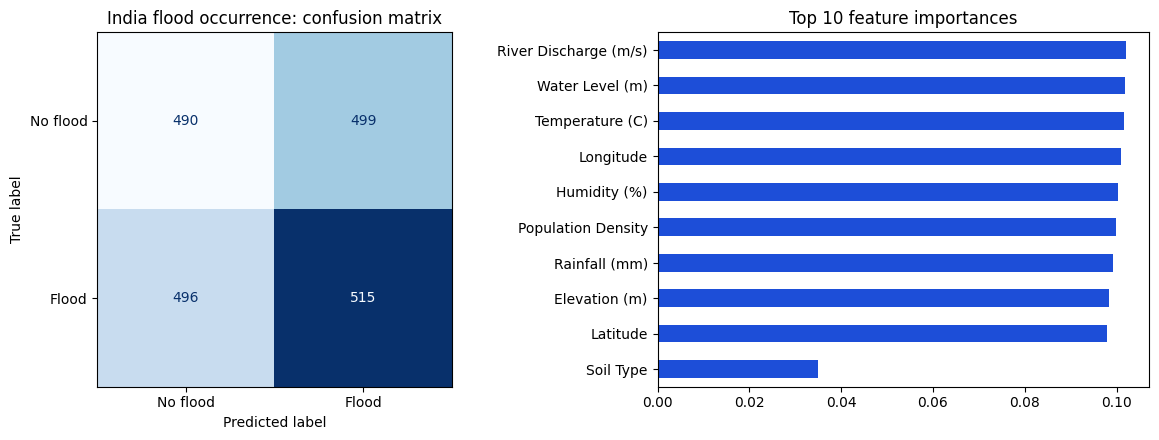

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te_f, pred_f), display_labels=["No flood", "Flood"]).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("India flood occurrence: confusion matrix")
imp = pd.Series(best_rf_flood.feature_importances_, index=X_f.columns).sort_values().tail(10)
imp.plot(kind="barh", ax=axes[1], color="#1D4ED8"); axes[1].set_title("Top 10 feature importances")
plt.tight_layout(); plt.show()

## Model 2: flood probability regression (`FloodProbability`, `flood1.csv`)

R2: 0.7316 | RMSE: 0.0259


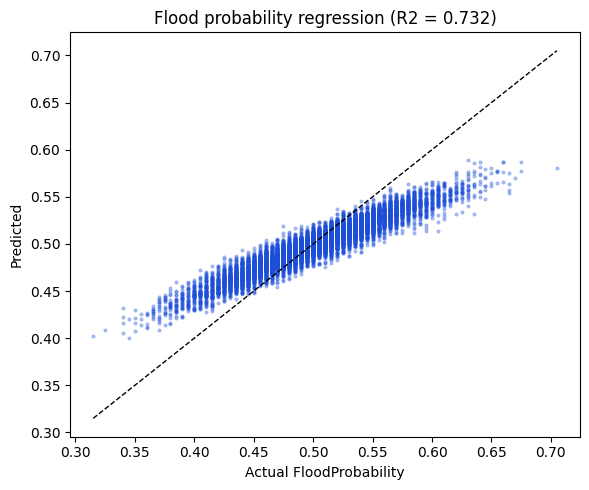

In [7]:
df_fp = pd.read_csv(FLOOD_CSV)
X_fp = df_fp.drop(columns=[C.FLOOD_TARGET]); y_fp = df_fp[C.FLOOD_TARGET]
X_tr_fp, X_te_fp, y_tr_fp, y_te_fp = train_test_split(X_fp, y_fp, test_size=0.2, random_state=C.SEED)
rf_reg = RandomForestRegressor(n_estimators=200, max_depth=20, random_state=C.SEED, n_jobs=-1).fit(X_tr_fp, y_tr_fp)
pred_fp = rf_reg.predict(X_te_fp)
r2 = r2_score(y_te_fp, pred_fp); rmse = float(np.sqrt(mean_squared_error(y_te_fp, pred_fp)))
print(f"R2: {r2:.4f} | RMSE: {rmse:.4f}")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_te_fp, pred_fp, s=4, alpha=0.3, color="#1D4ED8")
lims = [float(y_te_fp.min()), float(y_te_fp.max())]; ax.plot(lims, lims, "k--", lw=1)
ax.set_xlabel("Actual FloodProbability"); ax.set_ylabel("Predicted"); ax.set_title(f"Flood probability regression (R2 = {r2:.3f})")
plt.tight_layout(); plt.show()

## Model 3: earthquake severity (Random Forest, 200,000-row sample)

In [8]:
X_eq, y_eq, info = load_earthquakes(EQ_PATH)
print(info)
data_eq = X_eq.assign(severity=y_eq)
sample = data_eq.sample(n=200_000, random_state=C.SEED)
Xs, ys = sample[C.EQ_FEATURES], sample["severity"]
print("Sample class counts:", {C.SEVERITY_LABELS[i]: int((ys == i).sum()) for i in range(3)})
X_tr_e, X_te_e, y_tr_e, y_te_e = train_test_split(Xs, ys, test_size=0.2, random_state=C.SEED, stratify=ys)
rf_eq = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_split=5, random_state=C.SEED,
                               n_jobs=-1, class_weight="balanced").fit(X_tr_e, y_tr_e)
pred_e = rf_eq.predict(X_te_e)
eq_acc = accuracy_score(y_te_e, pred_e); eq_f1 = f1_score(y_te_e, pred_e, average="macro")
eq_base = float((y_te_e == int(np.bincount(y_te_e).argmax())).mean())
print(f"accuracy {eq_acc:.4f} | macro F1 {eq_f1:.4f} | majority baseline {eq_base:.4f}")
print(classification_report(y_te_e, pred_e, target_names=C.SEVERITY_LABELS))

{'rows_raw': 3445751, 'rows_dropped_missing': 0, 'rows_dropped_invalid_magnitude': 647, 'rows_used': 3445104}
Sample class counts: {'Low': 177812, 'Medium': 21924, 'High': 264}


accuracy 0.9732 | macro F1 0.6232 | majority baseline 0.8891
              precision    recall  f1-score   support

         Low       0.99      0.98      0.99     35562
      Medium       0.84      0.93      0.88      4385
        High       0.00      0.00      0.00        53

    accuracy                           0.97     40000
   macro avg       0.61      0.64      0.62     40000
weighted avg       0.97      0.97      0.97     40000



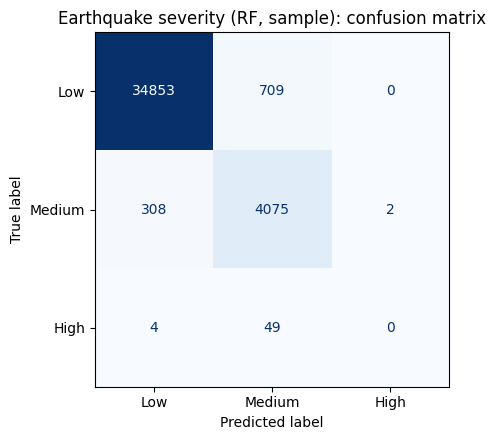

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te_e, pred_e), display_labels=C.SEVERITY_LABELS).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Earthquake severity (RF, sample): confusion matrix")
plt.tight_layout(); plt.show()

## Summary

In [10]:
summary = pd.DataFrame([
    ["India flood occurrence", "Random Forest + GridSearchCV", "accuracy", round(final_acc, 4), "see baseline printed above"],
    ["Flood probability", "Random Forest regressor", "R2", round(r2, 4), "-"],
    ["Earthquake severity (200k sample)", "Random Forest, balanced class weights", "macro F1", round(eq_f1, 4), f"accuracy {eq_acc:.4f} vs majority baseline {eq_base:.4f}"],
], columns=["Model", "Algorithm", "Metric", "Score", "Note"])
print(summary.to_string(index=False))

                            Model                             Algorithm   Metric  Score                                        Note
           India flood occurrence          Random Forest + GridSearchCV accuracy 0.5025                  see baseline printed above
                Flood probability               Random Forest regressor       R2 0.7316                                           -
Earthquake severity (200k sample) Random Forest, balanced class weights macro F1 0.6232 accuracy 0.9732 vs majority baseline 0.8891
